# Maíz grano de primavera-verano en Guanajuato y Querétaro
Una observación corresponde a un municipio, año y modalidad. Los porcentajes de eventos dan el mismo peso a cada observación. La superficie siniestrada por año se suma en hectáreas.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
from src import config

oro = pd.read_parquet(config.ORO / "dataset_maestro.parquet")
colores = {"Riego": "#21618C", "Temporal": "#A04319"}
print(oro.shape, oro.cvegeo.nunique(), oro.anio.min(), oro.anio.max())

(2776, 41) 64 2003 2025


In [2]:
tasas = []
for grupo, tabla in [("Total", oro), *oro.groupby("modalidad")]:
    s = tabla.siniestralidad.dropna()
    for corte in [0, config.UMBRAL_PERDIDA, .25, .5]:
        eventos = int(s.gt(corte).sum())
        tasas.append((grupo, corte, eventos, len(s), 100 * eventos / len(s)))
umbrales = pd.DataFrame(tasas, columns=["grupo", "umbral_estricto", "eventos", "validos", "porcentaje"])
umbrales.to_csv(config.REPORTES / "umbrales_3_3.csv", index=False)
umbrales.round(2)

,grupo,umbral_estricto,eventos,validos,porcentaje
0,Total,0.00,905,2776,32.60
1,Total,0.10,594,2776,21.40
2,Total,0.25,415,2776,14.95
3,Total,0.50,287,2776,10.34
4,Riego,0.00,210,1306,16.08
5,Riego,0.10,76,1306,5.82
6,Riego,0.25,28,1306,2.14
7,Riego,0.50,11,1306,0.84
8,Temporal,0.00,695,1470,47.28
9,Temporal,0.10,518,1470,35.24


In [3]:
estadisticos = []
for modalidad, tabla in oro.groupby("modalidad"):
    for variable in ["siniestralidad", "rendimiento_t_ha", "lluvia_floracion_mm"]:
        s = tabla[variable]
        q1, mediana, q3 = s.quantile([.25, .5, .75])
        estadisticos.append([modalidad, variable, mediana, q1, q3, q3-q1, s.min(), s.max(), s.isna().sum()])
resumen = pd.DataFrame(estadisticos, columns=["modalidad", "variable", "mediana", "q1", "q3", "ric", "min", "max", "faltantes"])
resumen.to_csv(config.REPORTES / "estadisticos_3_3.csv", index=False)
resumen.round(3)

,modalidad,variable,mediana,q1,q3,ric,min,max,faltantes
0,Riego,siniestralidad,0.00,0.000,0.000,0.000,0.00,1.00,0
1,Riego,rendimiento_t_ha,8.50,7.000,9.385,2.385,0.00,12.43,3
2,Riego,lluvia_floracion_mm,92.50,71.950,121.260,49.310,19.61,430.55,0
3,Temporal,siniestralidad,0.00,0.000,0.291,0.291,0.00,1.00,0
4,Temporal,rendimiento_t_ha,1.20,0.600,2.278,1.677,0.00,5.85,0
5,Temporal,lluvia_floracion_mm,90.01,67.872,120.090,52.218,19.61,430.55,0


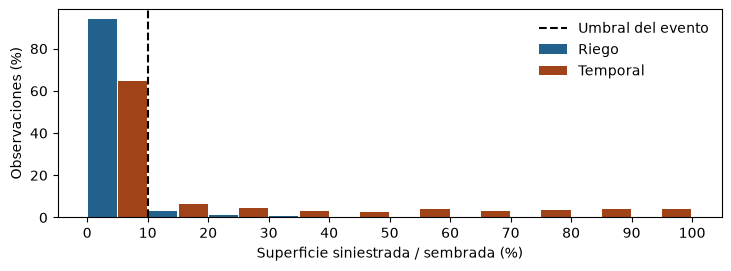

In [4]:
def distribucion(tabla):
    """Distribución porcentual dentro de cada modalidad, intervalos de diez puntos."""
    fig, ax = plt.subplots(figsize=(7.2, 2.6), layout="constrained")
    bins = np.linspace(0, 100, 11)
    for i, (modo, grupo) in enumerate(tabla.groupby("modalidad")):
        s = grupo.siniestralidad.dropna()
        valores, _ = np.histogram(100*s, bins=bins)
        ax.bar(bins[:-1]+(2.5+5*i), valores*100/len(s), width=4.8, color=colores[modo], label=modo)
    ax.axvline(config.UMBRAL_PERDIDA*100, color="black", linestyle="--", label="Umbral del evento")
    ax.set(xlabel="Superficie siniestrada / sembrada (%)", ylabel="Observaciones (%)", xticks=bins)
    ax.legend(frameon=False)
    fig.savefig(config.FIGURAS / "fig_3_3_siniestralidad.png", dpi=300)
    plt.show()

distribucion(oro)

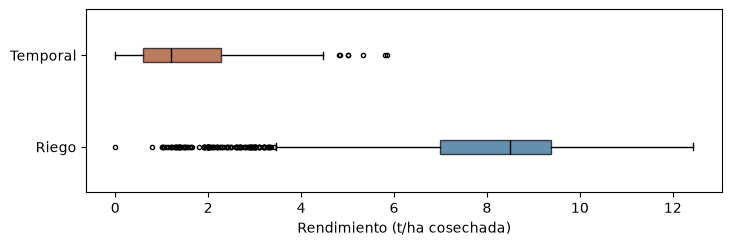

In [5]:
def rendimiento(tabla):
    """Caja entre cuartiles con mediana, bigotes de 1.5 RIC y puntos extremos."""
    fig, ax = plt.subplots(figsize=(7.2, 2.35), layout="constrained")
    grupos = [tabla.loc[tabla.modalidad.eq(m), "rendimiento_t_ha"].dropna() for m in colores]
    cajas = ax.boxplot(grupos, orientation="horizontal", tick_labels=list(colores), patch_artist=True,
                       medianprops={"color":"black"}, flierprops={"markersize":3})
    for caja, color in zip(cajas["boxes"], colores.values()):
        caja.set_facecolor(color)
        caja.set_alpha(.7)
    ax.set_xlabel("Rendimiento (t/ha cosechada)")
    fig.savefig(config.FIGURAS / "fig_3_3_rendimiento.png", dpi=300)
    plt.show()

rendimiento(oro)

In [6]:
pares = oro.loc[oro.modalidad.eq("Temporal"), ["lluvia_floracion_mm", "rendimiento_t_ha"]].dropna()
rho = pares.corr(method="spearman").iloc[0, 1]
print(f"Spearman en temporal: {rho:.4f} ({len(pares)} pares). Asociación descriptiva.")
anios = oro.groupby("anio").agg(siniestrada_ha=("siniestrada_ha", "sum"), sembrada_ha=("sembrada_ha", "sum"),
                                eventos=("siniestralidad", lambda s: s.gt(config.UMBRAL_PERDIDA).sum()))
anios["pct_superficie"] = 100 * anios.siniestrada_ha / anios.sembrada_ha
anios.sort_values("siniestrada_ha", ascending=False).head(3)

Spearman en temporal: 0.4250 (1470 pares). Asociación descriptiva.


,siniestrada_ha,sembrada_ha,eventos,pct_superficie
anio,,,,
2011,255924.05,506377.55,62,50.540165
2009,239694.63,494780.68,62,48.444622
2005,202863.98,493353.00,55,41.119438


El cotejo externo de los tres años con más hectáreas siniestradas se reproduce con `python -m src.etl.contraste_sequia`. Mantiene el histórico del SMN separado de las variables del modelo.